# 4 · Classify: can this patch of ocean fuel a strong cyclone?

**Syllabus:** Module 4 (logistic regression, KNN, decision trees, model evaluation).

A cyclone is a heat engine: it draws energy from warm water. The fuel is measured by
the **tropical cyclone heat potential (TCHP)**, the heat stored in the water warmer
than 26 °C, in kJ per cm² of sea surface. Above about **50 kJ/cm²** the ocean can
usually support a cyclone strengthening, provided the atmosphere cooperates (NOAA
*State of the Climate 2020*, after Shay et al. 2000 and Mainelli et al. 2008).

TCHP depends on how deep the warm water goes, which a satellite cannot see. So:

**Can we classify each patch of ocean as "fuel ≥ 50 kJ/cm²" (yes or no) from
satellite data alone?**

The labels for training come from GLORYS profiles (2010–2020). The test labels are
measured: the TCHP of each held-out Argo float, 2023–2024.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score)
import common as C

C.style()
cells, casts = C.load_cells(), C.load_casts()
for d in (cells, casts):
    d["log_bathy"] = np.log10(d["bathy"].clip(lower=1))
FEATURES = C.INPUTS + ["lat", "lon", "log_bathy", "doy_sin", "doy_cos"]

cells["tchp"] = [C.tchp(p) for p in C.profiles(cells, "")]
casts["tchp_obs"] = [C.tchp(p) for p in C.profiles(casts, "obs_")]
for name, col in [("hybrid", "hybrid (selected)|"), ("climatology", "climatology|"), ("glorys", "GLORYS (ceiling)|")]:
    casts[f"tchp_{name}"] = [C.tchp(p) for p in C.profiles(casts, col)]

cells = cells.dropna(subset=["tchp"])
casts_l = casts.dropna(subset=["tchp_obs"] + FEATURES).copy()
cells["fuel"] = (cells["tchp"] >= C.TCHP_THRESHOLD).astype(int)
casts_l["fuel"] = (casts_l["tchp_obs"] >= C.TCHP_THRESHOLD).astype(int)
train, val = cells[cells["split"] == "train"], cells[cells["split"] == "val"]
print(f"Argo casts with a measurable TCHP: {len(casts_l):,} of {len(casts):,}")

Argo casts with a measurable TCHP: 5,793 of 6,144


## 4.1 How balanced are the classes?

In [2]:
balance = pd.DataFrame({"train (GLORYS)": train["fuel"].value_counts(normalize=True),
                        "validation (GLORYS)": val["fuel"].value_counts(normalize=True),
                        "test (Argo)": casts_l["fuel"].value_counts(normalize=True)}).mul(100).round(1)
balance.index = ["below 50 kJ/cm²", "fuel ≥ 50 kJ/cm²"]
C.record("classify.balance_pct", balance.to_dict())
C.record("classify.casts_labelled", len(casts_l))
balance

,train (GLORYS),validation (GLORYS),test (Argo)
below 50 kJ/cm²,53.4,57.9,51.1
fuel ≥ 50 kJ/cm²,46.6,42.1,48.9


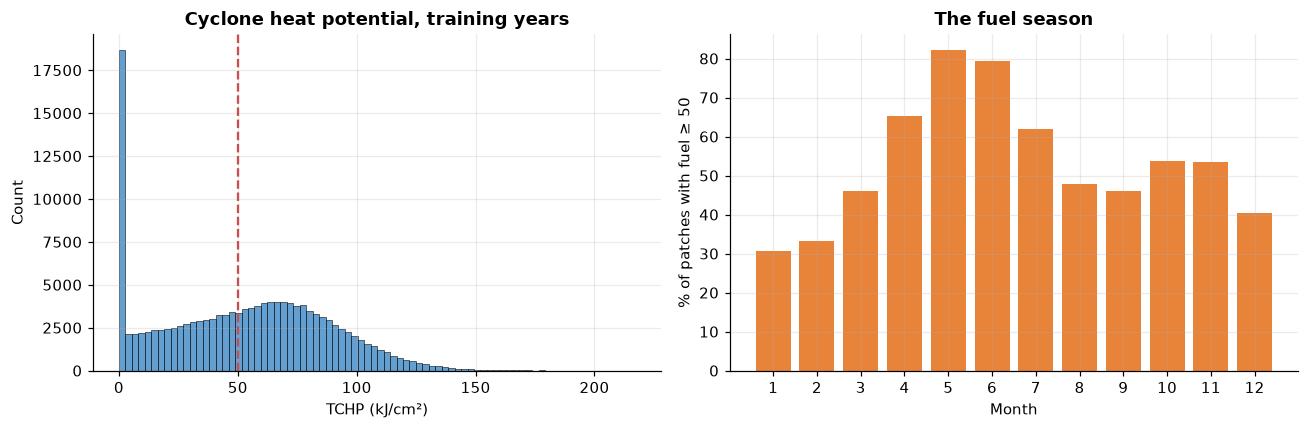

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["tchp"], bins=80, ax=axes[0], color=C.PALETTE["course"])
axes[0].axvline(C.TCHP_THRESHOLD, color=C.PALETTE["accent"], ls="--"); axes[0].set_xlabel("TCHP (kJ/cm²)")
axes[0].set_title("Cyclone heat potential, training years")
m = train.groupby(train["day"].dt.month)["fuel"].mean().mul(100)
axes[1].bar(m.index, m.values, color=C.PALETTE["deep"]); axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("Month"); axes[1].set_ylabel("% of patches with fuel ≥ 50"); axes[1].set_title("The fuel season")
fig.tight_layout(); C.save(fig, "classify_balance")

Neither class is rare, but they are not 50/50 either. With imbalanced classes,
**accuracy alone misleads**: a model that always answers the majority class scores
its share for free. So we also report precision, recall, F1 and the area under the
ROC curve.

## 4.2 Three classifiers, settings chosen on the validation years

In [4]:
def make(method, p):
    if method == "Logistic regression":
        return make_pipeline(StandardScaler(), LogisticRegression(C=p, max_iter=2000))
    if method == "KNN":
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=p, n_jobs=-1))
    return make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=p, min_samples_leaf=20, random_state=C.SEED))


grid = {"Logistic regression": [0.01, 1.0, 100.0], "KNN": [10, 50, 100], "Decision tree": [4, 8, 12, 16]}
tune = []
for method, params in grid.items():
    for p in params:
        m = make(method, p).fit(train[FEATURES], train["fuel"])
        tune.append({"method": method, "setting": p, "val_auc": roc_auc_score(val["fuel"], m.predict_proba(val[FEATURES])[:, 1])})
tune = pd.DataFrame(tune).round(4)
chosen = tune.loc[tune.groupby("method")["val_auc"].idxmax()].set_index("method")["setting"].to_dict()
chosen = {k: (float(v) if k == "Logistic regression" else int(v)) for k, v in chosen.items()}   # the table stores every setting as a float
C.record("classify.tuning", tune.to_dict("records")); C.record("classify.chosen", chosen)
tune

,method,setting,val_auc
0,Logistic regression,0.01,0.9609
1,Logistic regression,1.00,0.9609
2,Logistic regression,100.00,0.9609
3,KNN,10.00,0.9647
4,KNN,50.00,0.9737
5,KNN,100.00,0.9737
6,Decision tree,4.00,0.9270
7,Decision tree,8.00,0.9543
8,Decision tree,12.00,0.9599
9,Decision tree,16.00,0.9531


## 4.3 The test on real floats

In [5]:
models = {k: make(k, chosen[k]).fit(train[FEATURES], train["fuel"]) for k in grid}
y = casts_l["fuel"].to_numpy()
proba = {k: m.predict_proba(casts_l[FEATURES])[:, 1] for k, m in models.items()}
# The other route: reconstruct the whole profile, then compute TCHP from it.
routes = {"Satelight hybrid → TCHP": "tchp_hybrid", "Climatology → TCHP": "tchp_climatology", "GLORYS → TCHP": "tchp_glorys"}


def metrics(y, yhat, score=None):
    out = {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat), "recall": recall_score(y, yhat),
           "F1": f1_score(y, yhat)}
    if score is not None:
        out["ROC AUC"] = roc_auc_score(y, score)
    return out


rows = {k: metrics(y, (p >= 0.5).astype(int), p) for k, p in proba.items()}
for k, col in routes.items():
    v = casts_l[col].to_numpy()
    ok = np.isfinite(v)
    rows[k] = metrics(y[ok], (v[ok] >= C.TCHP_THRESHOLD).astype(int), v[ok]) | {"casts": int(ok.sum())}
res = pd.DataFrame(rows).T.round(3)
res["always 'fuel' (baseline)"] = np.nan
baseline = metrics(y, np.ones_like(y))
C.record("classify.test", res.drop(columns="always 'fuel' (baseline)").to_dict(orient="index"))
C.record("classify.majority_baseline", baseline)
print("Baseline, always answer the majority class:", {k: round(v, 3) for k, v in baseline.items()})
res.drop(columns="always 'fuel' (baseline)")

Baseline, always answer the majority class: {'accuracy': 0.511, 'precision': 0.511, 'recall': 1.0, 'F1': 0.676}


,accuracy,precision,recall,F1,ROC AUC,casts
Logistic regression,0.884,0.845,0.946,0.893,0.955,NaN
KNN,0.894,0.904,0.886,0.895,0.965,NaN
Decision tree,0.890,0.886,0.902,0.894,0.957,NaN
Satelight hybrid → TCHP,0.907,0.918,0.898,0.908,0.972,5790.0
Climatology → TCHP,0.839,0.934,0.736,0.823,0.944,5790.0
GLORYS → TCHP,0.924,0.905,0.952,0.928,0.979,5790.0


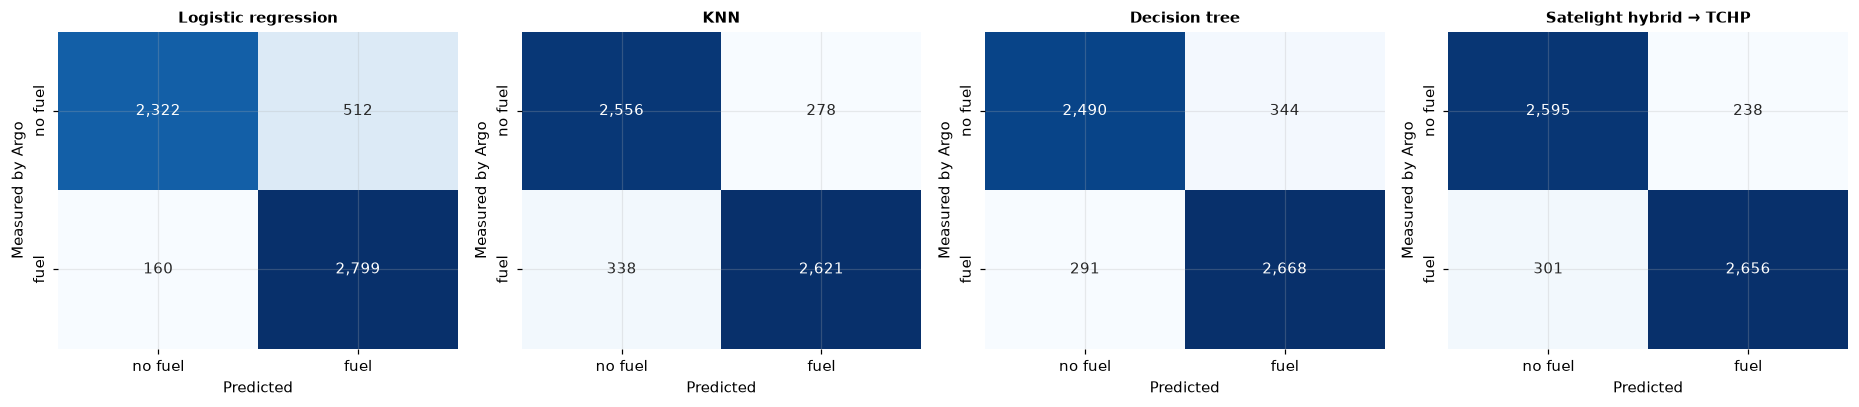

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
show = list(models) + ["Satelight hybrid → TCHP"]
for ax, k in zip(axes, show):
    if k in proba:
        cm = confusion_matrix(y, (proba[k] >= 0.5).astype(int))
    else:
        v = casts_l[routes[k]].to_numpy(); ok = np.isfinite(v)
        cm = confusion_matrix(y[ok], (v[ok] >= C.TCHP_THRESHOLD).astype(int))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no fuel", "fuel"], yticklabels=["no fuel", "fuel"])
    ax.set_title(k, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Measured by Argo")
fig.tight_layout(); C.save(fig, "classify_confusion")
cms = {k: confusion_matrix(y, (proba[k] >= 0.5).astype(int)).tolist() for k in models}
for k, col in routes.items():
    v = casts_l[col].to_numpy(); ok = np.isfinite(v)
    cms[k] = confusion_matrix(y[ok], (v[ok] >= C.TCHP_THRESHOLD).astype(int)).tolist()
C.record("classify.confusion", cms)

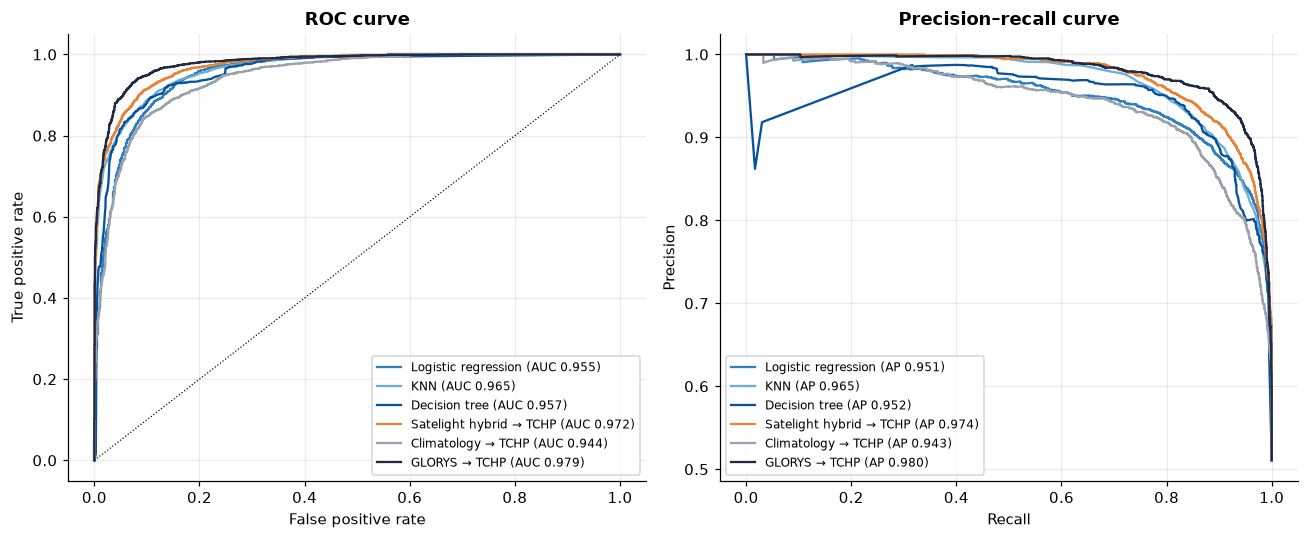

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = dict(zip(list(models) + list(routes), ["#2f7fc1", "#6baed6", "#08519c", C.PALETTE["deep"], C.PALETTE["climatology"], C.PALETTE["glorys"]]))
for k in list(models) + list(routes):
    if k in proba:
        yy, s = y, proba[k]
    else:
        v = casts_l[routes[k]].to_numpy(); ok = np.isfinite(v); yy, s = y[ok], v[ok]
    fpr, tpr, _ = roc_curve(yy, s); pr, rc, _ = precision_recall_curve(yy, s)
    keep = np.unique(np.linspace(0, len(fpr) - 1, 120).astype(int))
    C.record(f"classify.roc.{k}", {"fpr": fpr[keep].round(4), "tpr": tpr[keep].round(4), "auc": roc_auc_score(yy, s)})
    axes[0].plot(fpr, tpr, color=colors[k], label=f"{k} (AUC {roc_auc_score(yy, s):.3f})")
    axes[1].plot(rc, pr, color=colors[k], label=f"{k} (AP {average_precision_score(yy, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curve")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout(); C.save(fig, "classify_roc_pr")

## 4.4 Looking inside the classifiers

A logistic regression is a weighted sum passed through an S-curve, so its weights can
be read directly: a positive weight pushes towards "fuel". Inputs were standardised, so
the weights are comparable with each other.

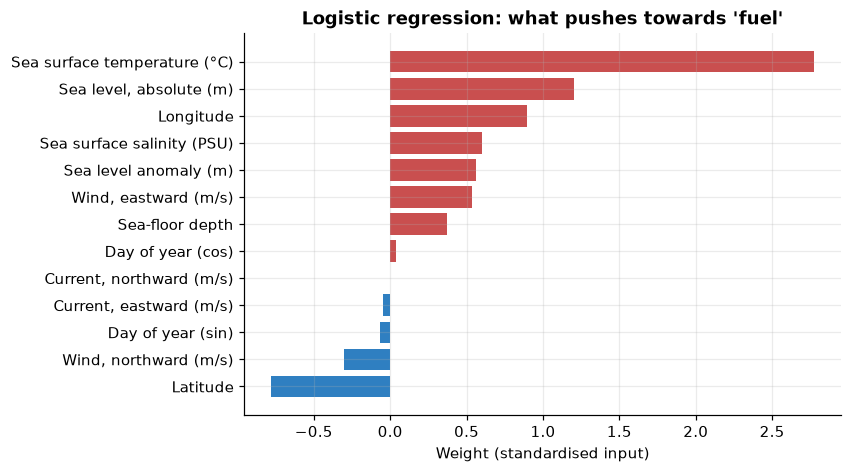

In [8]:
logit = models["Logistic regression"][-1]
coef = pd.Series(logit.coef_[0], index=FEATURES).rename(index={**C.INPUT_NAMES, "lat": "Latitude", "lon": "Longitude",
                 "log_bathy": "Sea-floor depth", "doy_sin": "Day of year (sin)", "doy_cos": "Day of year (cos)"}).sort_values()
C.record("classify.logistic_coef", coef.round(3).to_dict())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coef.index, coef.values, color=[C.PALETTE["accent"] if v > 0 else C.PALETTE["course"] for v in coef.values])
ax.set_xlabel("Weight (standardised input)"); ax.set_title("Logistic regression: what pushes towards 'fuel'")
C.save(fig, "classify_logistic_weights")

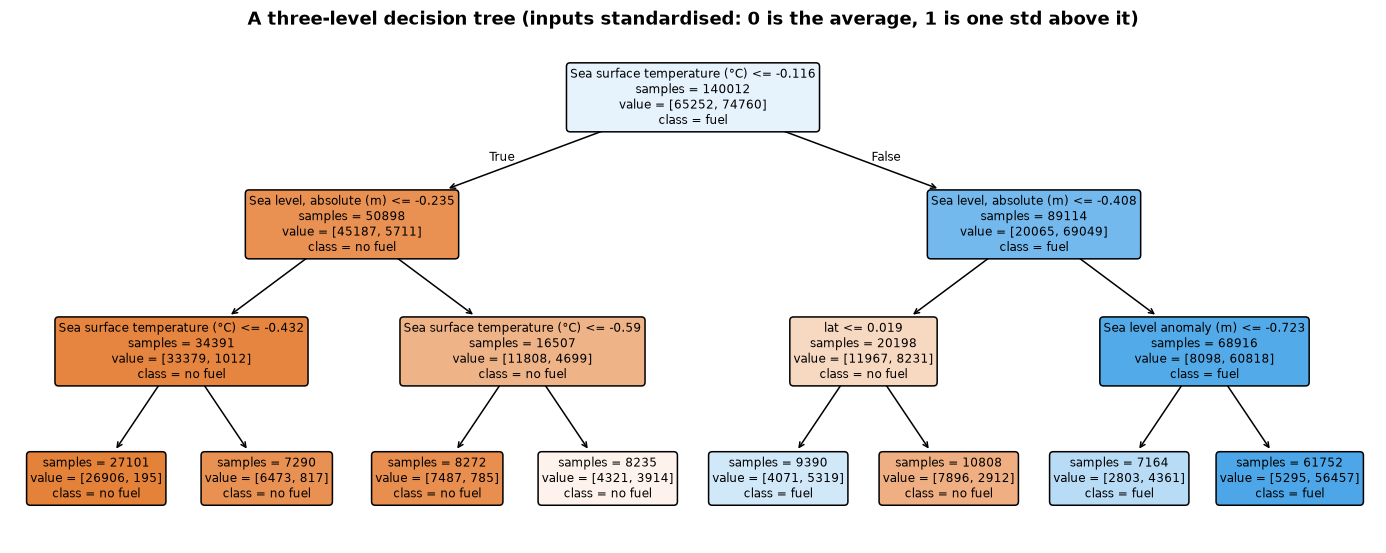

In [9]:
small = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=C.SEED)).fit(train[FEATURES], train["fuel"])
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(small[-1], feature_names=[C.INPUT_NAMES.get(f, f) for f in FEATURES], class_names=["no fuel", "fuel"],
          filled=True, rounded=True, fontsize=8, impurity=False, ax=ax)
ax.set_title("A three-level decision tree (inputs standardised: 0 is the average, 1 is one std above it)")
C.save(fig, "classify_tree")

## 4.5 Where the classifier is right and wrong

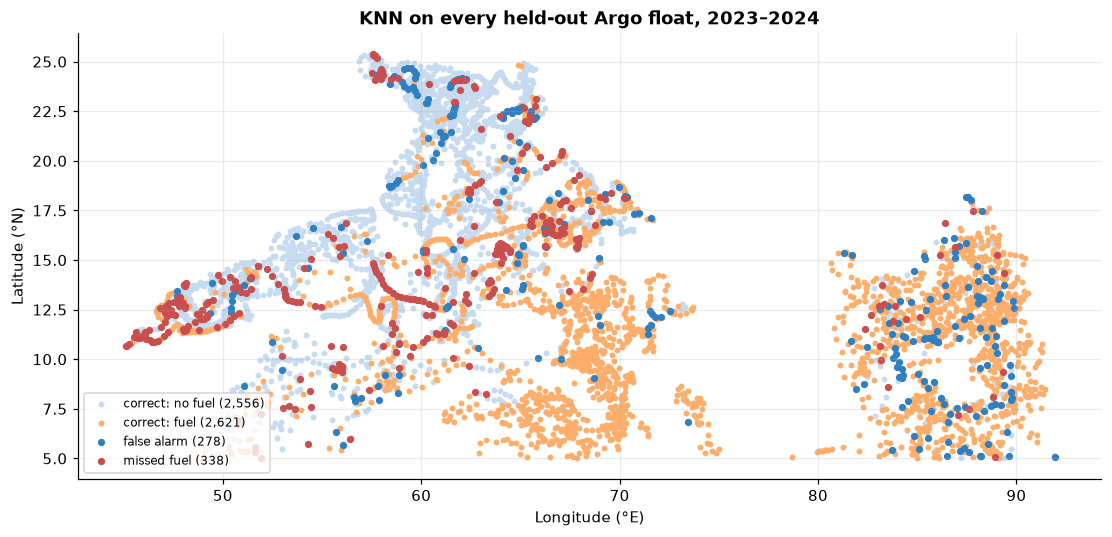

In [10]:
best = max(models, key=lambda k: f1_score(y, (proba[k] >= 0.5).astype(int)))
pred = (proba[best] >= 0.5).astype(int)
kind = np.select([(y == 1) & (pred == 1), (y == 0) & (pred == 0), (y == 0) & (pred == 1), (y == 1) & (pred == 0)],
                 ["correct: fuel", "correct: no fuel", "false alarm", "missed fuel"], default="")
fig, ax = plt.subplots(figsize=(12, 5.5))
for k, col in [("correct: no fuel", "#c6dbef"), ("correct: fuel", "#fdae6b"), ("false alarm", C.PALETTE["course"]), ("missed fuel", C.PALETTE["accent"])]:
    s = kind == k
    ax.scatter(casts_l.loc[s, "lon"], casts_l.loc[s, "lat"], s=8 if "correct" in k else 14, color=col, label=f"{k} ({s.sum():,})")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8); ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title(f"{best} on every held-out Argo float, 2023–2024")
C.save(fig, "classify_map")
C.record("classify.best", best)